In [45]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

# We will generate a truly balanced dataset of 1000 records (500 naturally Approved, 500 naturally Rejected)
# to prevent a ranked split from overriding individual applicant logic.
target_records = 500
approved_records = []
rejected_records = []

# Unique user base profiles
num_users = 200
user_ids = [f"USR_{i:03d}" for i in range(1, num_users + 1)]
user_profiles = {
    user_id: {
        "Age": np.random.randint(21, 65),
        "Income": np.random.randint(30000, 150000),
        "Credit_Score": np.random.randint(500, 850)
    }
    for user_id in user_ids
}

purposes = ["Home", "Auto", "Education", "Personal", "Business"]

# Generate until we have exactly 500 Approved and 500 Rejected
while len(approved_records) < target_records or len(rejected_records) < target_records:
    user_id = np.random.choice(user_ids)
    profile = user_profiles[user_id]

    credit_score = profile["Credit_Score"]
    income = profile["Income"]
    loan_amount = np.random.randint(1000, 50000)
    purpose = np.random.choice(purposes)

    # Determine status via logical absolute rules
    # 1. Base score derived from Credit Score & Income
    score_factor = (credit_score - 500) / 350  # 0 to 1
    income_factor = income / 150000            # 0 to 1

    # 2. Strong penalty for high loan-to-income ratio
    loan_to_income = loan_amount / income

    # Decision criteria
    decision_metric = (score_factor * 0.5) + (income_factor * 0.3) - (loan_to_income * 0.4)

    # Absolute logic: Approved if decision_metric is high, or if it's a very small loan for a decent score
    if decision_metric > 0.15 or (loan_amount < 5000 and credit_score >= 600):
        status = 'Approved'
    else:
        status = 'Rejected'

    record = {
        "User_ID": user_id,
        "Age": profile["Age"],
        "Income": income,
        "Credit_Score": credit_score,
        "Loan_Amount": loan_amount,
        "Loan_Purpose": purpose,
        "Loan_Status": status
    }

    if status == 'Approved' and len(approved_records) < target_records:
        approved_records.append(record)
    elif status == 'Rejected' and len(rejected_records) < target_records:
        rejected_records.append(record)

# Combine and shuffle
balanced_data = approved_records + rejected_records
df = pd.DataFrame(balanced_data)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

# Display dataset information and sample
print(f"Dataset Shape: {df.shape}")
print(f"Unique Users: {df['User_ID'].nunique()}")
print(f"Approval Split:\n{df['Loan_Status'].value_counts()}")
print("\nFirst 10 rows of the balanced dataset:")
print(df.head(10))

Dataset Shape: (1000, 7)
Unique Users: 195
Approval Split:
Loan_Status
Rejected    500
Approved    500
Name: count, dtype: int64

First 10 rows of the balanced dataset:
   User_ID  Age  Income  Credit_Score  Loan_Amount Loan_Purpose Loan_Status
0  USR_047   29   30206           514         3048         Auto    Rejected
1  USR_183   54   87458           604        38055         Home    Rejected
2  USR_151   43   31150           628        27113    Education    Rejected
3  USR_102   22   32869           662        35518         Home    Rejected
4  USR_194   37  140448           561        38873         Home    Approved
5  USR_157   46   97215           585        41379         Auto    Rejected
6  USR_027   51   41534           714        49689    Education    Rejected
7  USR_047   29   30206           514         6240    Education    Rejected
8  USR_102   22   32869           662        31573     Personal    Rejected
9  USR_039   28  108603           532         2970    Education    Appr

In [46]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Prepare features (X) and target (y)
y = df['Loan_Status'].map({'Approved': 1, 'Rejected': 0})
X = df.drop(columns=['User_ID', 'Loan_Status'])

# 2. Identify numerical and categorical columns
num_cols = ['Age', 'Income', 'Credit_Score', 'Loan_Amount']
cat_cols = ['Loan_Purpose']

# 3. Set up preprocessor: one-hot encode categoricals, standardize numericals
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first'), cat_cols)
    ]
)

# 4. Split data into training and validation sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 5. Fit preprocessor and transform data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Get feature names after preprocessing
encoded_cat_features = preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols).tolist()
all_features = num_cols + encoded_cat_features

# 6. Train the Logistic Regression model
model = LogisticRegression(random_state=42)
model.fit(X_train_processed, y_train)

# 7. Make predictions
y_pred = model.predict(X_test_processed)

# 8. Evaluate results
accuracy = accuracy_score(y_test, y_pred)
print(f"Updated Model Accuracy: {accuracy:.4f}\n")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Rejected', 'Approved']))

# Show feature coefficients
coefficients = pd.DataFrame({
    'Feature': all_features,
    'Coefficient': model.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

print("\nLogistic Regression Coefficients:")
display(coefficients)

Updated Model Accuracy: 0.9550

Confusion Matrix:
[[96  4]
 [ 5 95]]

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.95      0.96      0.96       100
    Approved       0.96      0.95      0.95       100

    accuracy                           0.95       200
   macro avg       0.96      0.95      0.95       200
weighted avg       0.96      0.95      0.95       200


Logistic Regression Coefficients:


,Feature,Coefficient
1,Income,4.699959
2,Credit_Score,4.311211
0,Age,0.105742
6,Loan_Purpose_Home,-0.043416
5,Loan_Purpose_Education,-0.059573
4,Loan_Purpose_Business,-0.294978
7,Loan_Purpose_Personal,-0.685104
3,Loan_Amount,-2.718938


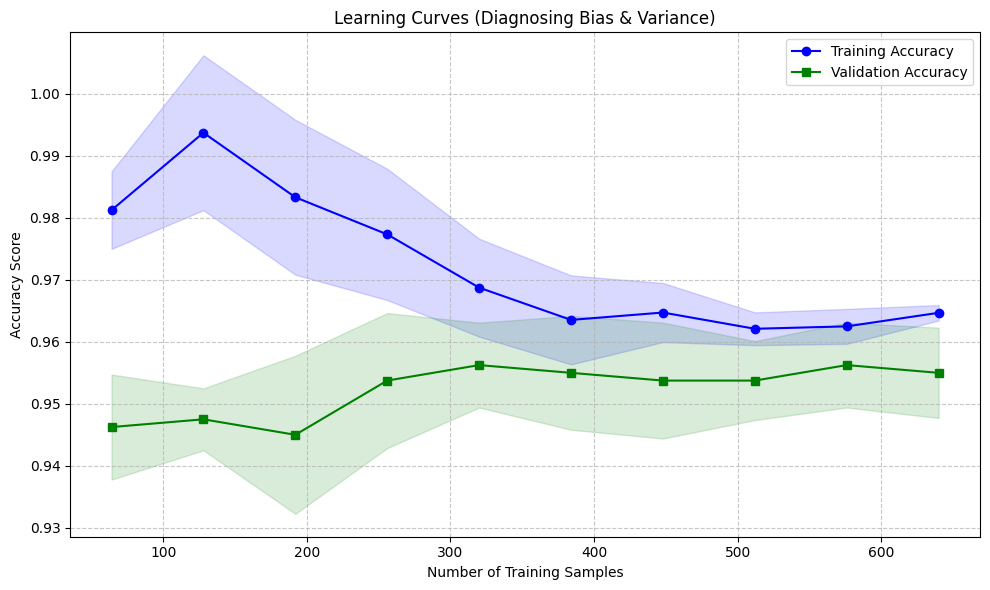

In [47]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

# 1. Compute Learning Curve data
train_sizes, train_scores, test_scores = learning_curve(
    estimator=model,
    X=X_train_processed,
    y=y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42
)

# 2. Calculate mean and standard deviation for training and test scores
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

# 3. Plot the learning curve
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, 'o-', color='blue', label='Training Accuracy')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='blue')

plt.plot(train_sizes, test_mean, 's-', color='green', label='Validation Accuracy')
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.15, color='green')

plt.title('Learning Curves (Diagnosing Bias & Variance)')
plt.xlabel('Number of Training Samples')
plt.ylabel('Accuracy Score')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(loc='best')
plt.tight_layout()
plt.show()

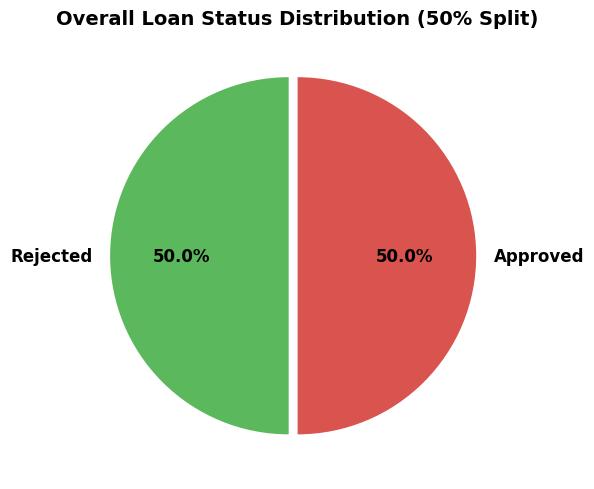

In [48]:
import matplotlib.pyplot as plt

# 1. Count the occurrences of Approved and Rejected loan applications
status_counts = df['Loan_Status'].value_counts()

# 2. Plot the distribution as a pie chart
plt.figure(figsize=(6, 6))
plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#5cb85c', '#d9534f'],
    explode=(0.05, 0),
    textprops={'fontsize': 12, 'weight': 'bold'}
)
plt.title('Overall Loan Status Distribution (50% Split)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [49]:
#@title ### Test the Model with Custom Inputs

import pandas as pd
import numpy as np
import ipywidgets as widgets
from IPython.display import display, HTML

# Create input fields
age_input = widgets.IntSlider(value=35, min=21, max=100, step=1, description='Age:')
income_input = widgets.IntText(value=60000, description='Income ($):')
credit_score_input = widgets.IntSlider(value=650, min=300, max=850, step=1, description='Credit Score:')
loan_amount_input = widgets.IntText(value=15000, description='Loan Amount ($):')
loan_purpose_input = widgets.Dropdown(
    options=['Home', 'Auto', 'Education', 'Personal', 'Business'],
    value='Personal',
    description='Purpose:'
)

button = widgets.Button(description="Predict Loan Status", button_style='primary')
output = widgets.Output()

def make_prediction(b):
    with output:
        output.clear_output()

        # 1. Gather inputs into a DataFrame matching the model's expected format
        input_data = pd.DataFrame([{
            'Age': age_input.value,
            'Income': income_input.value,
            'Credit_Score': credit_score_input.value,
            'Loan_Amount': loan_amount_input.value,
            'Loan_Purpose': loan_purpose_input.value
        }])

        # Verification check to make sure dependencies exist
        if 'preprocessor' not in globals() or 'model' not in globals():
            display(HTML("<div style='padding: 10px; background-color: #fff3cd; color: #856404; border-radius: 5px; font-weight: bold;'>"
                         "Error: Please run the model training cell (cell 6d308336) first to initialize the preprocessor and model.</div>"))
            return

        # 2. Process inputs using the fitted preprocessor
        processed_input = preprocessor.transform(input_data)

        # 3. Predict probability and final class
        prob = model.predict_proba(processed_input)[0]
        prediction = model.predict(processed_input)[0]

        # 4. Display formatted result
        if prediction == 1:
            display(HTML(f"<div style='padding: 10px; background-color: #d4edda; color: #155724; border-radius: 5px; font-weight: bold;'>"
                         f"Prediction: APPROVED (Confidence: {prob[1]:.2%})</div>"))
        else:
            display(HTML(f"<div style='padding: 10px; background-color: #f8d7da; color: #721c24; border-radius: 5px; font-weight: bold;'>"
                         f"Prediction: REJECTED (Confidence: {prob[0]:.2%})</div>"))

button.on_click(make_prediction)

# Layout formulation
ui = widgets.VBox([
    widgets.HTML("<h4>Enter Loan Applicant Details:</h4>"),
    age_input,
    income_input,
    credit_score_input,
    loan_amount_input,
    loan_purpose_input,
    widgets.HTML("<br>"),
    button,
    widgets.HTML("<br>"),
    output
])

display(ui)

In [50]:
import numpy as np
import pandas as pd

# Let's inspect model predictions for a fixed applicant profile across various loan amounts
test_amounts = [1000, 2000, 5000, 10000, 20000, 30000, 40000, 50000]
results = []

for amt in test_amounts:
    temp_df = pd.DataFrame([{
        'Age': 35,
        'Income': 60000,
        'Credit_Score': 650,
        'Loan_Amount': amt,
        'Loan_Purpose': 'Personal'
    }])

    processed = preprocessor.transform(temp_df)
    prob = model.predict_proba(processed)[0]
    pred = model.predict(processed)[0]

    results.append({
        'Loan Amount ($)': amt,
        'Prediction': 'Approved' if pred == 1 else 'Rejected',
        'Approval Prob (%)': f"{prob[1]:.2%}",
        'Rejection Prob (%)': f"{prob[0]:.2%}"
    })

display(pd.DataFrame(results))

,Loan Amount ($),Prediction,Approval Prob (%),Rejection Prob (%)
0,1000,Approved,97.07%,2.93%
1,2000,Approved,96.44%,3.56%
2,5000,Approved,93.72%,6.28%
3,10000,Approved,84.64%,15.36%
4,20000,Rejected,42.93%,57.07%
5,30000,Rejected,9.31%,90.69%
6,40000,Rejected,1.38%,98.62%
7,50000,Rejected,0.19%,99.81%
